# Simulating absorption spectra in hydro simulations

KITP Program: [Building a Physical Understanding of Galaxy Evolution with Data-driven Astronomy](https://datadrivengalaxyevolution.github.io/)

Jan 18, 2023

[Mahdi Qezlou](https://mahdiqezlou.github.io/)


[![Open this notebook in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DataDrivenGalaxyEvolution/galevo23-tutorials/blob/main/week-1/Large_scale_galaxy_formation_simulations_and_machine_learning_approaches_Part1_Simulated_absorption_spectra.ipynb)



## [MP-Gadget](https://github.com/MP-Gadget/MP-Gadget):

- We particularly use `MP-Gadget` simulation in this tutorial.
- It is derived from the main P-Gadget / Gadget-2, but it is scalable to a million nodes.
- The largest run is ASTRID with L=250 cMpc/h and $2 \times 5500^3$ particles.

<p align="center">
  <img src="https://raw.githubusercontent.com/mahdiqezlou/MP-Gadget_L15n256/main/images/ASTRID.png" width=100/>
</p>

The physics models :

- Pressure Entropy SPH and Density Entropy SPH
- Radiation background in the expansion
- [Massive neutrinos](https://ui.adsabs.harvard.edu/abs/2018MNRAS.481.1486B/abstract)
- Dark energy
- [ICs have species-dependent density and velocity transfer functions](https://ui.adsabs.harvard.edu/abs/2020JCAP...06..002B/abstract)
- Generic halo tracer particle seeding
- Various wind feedback and [blackhole feedback](https://ui.adsabs.harvard.edu/abs/2022MNRAS.510..531C/abstract) models
- Various star formation criteria
- Primordial and metal cooling using updated recombination rates from the Sherwood simulation.
- [Helium reionization](https://ui.adsabs.harvard.edu/abs/2020MNRAS.496.4372U/abstract)
- [Fluctuating UV background](https://ui.adsabs.harvard.edu/abs/2022MNRAS.512.3703B/abstract)



## Extracting spectra from simulations :


### Physics :


![](https://raw.githubusercontent.com/mahdiqezlou/MP-Gadget_L15n256/main/images/Voronoi_SPH.png)

- Each particle is an absorber with density and temperature estimated using the simulation's kernel, i.e. Voronoi for AREPO and SPH for Gadget
- Assuming ionization equilibrium with uniform UVB, we calculate the fraction of elements at different ionization states.
- To estimate the optical depth for each ion, we convolve the density with the Voigt profiles assigned to the absorber closest to the line of sight.



### `fake_spectra` :
Here, we introduce the [`fake_spectra`](https://github.com/sbird/fake_spectra.git) package to extract simulated spectra from `MP-Gadget` simulations.

`fake_Spectra` is a small code for generating and analyzing simulated spectra from Arepo/Gadget. It is fast, parallel (Open-MP and MPI), and written in C++ and Python 3.


Let's install the required packages:

In [2]:
# ! pip install -q bigfile
# # we need a few ubuntu libraries which are not installed on collab
# ! sudo apt-get -qq install -y libgsl-dev libboost-test-dev
# ! pip install -q astropy

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# !pip install --no-build-isolation --no-cache-dir -q git+https://github.com/jibanCat/fake_spectra.git@float32patch

In [7]:
import h5py
from matplotlib import pyplot as plt
import numpy as np
from scipy.signal import find_peaks
from pathlib import Path


def find_DLAs_in_spectrum(file_path, path_append, n_spectra):
    """
    Calculates and plots the crossings of tau_spectrum against a threshold.
    Returns a flattened NumPy array of all crossing indices found across all spectra.
    """
    file_path_add = Path('/scratch/cavestru_root/cavestru0/mfho/priya/emu_full/')
    file_path = file_path_add / file_path / path_append
    fig, ax = plt.subplots(1,1, figsize=(15,6))

    all_crossing_points = [] # To collect all crossing indices
    total_crossings = 0 # counter for total crossings

    with h5py.File(file_path,'r') as f:
        for i in range(n_spectra):
            tau_spectrum = f['tau/H/1/1215'][i,:]
            log_tau_spectrum = np.log10(tau_spectrum)
            x_values = np.arange(len(log_tau_spectrum))

            ax.plot(x_values, log_tau_spectrum, color='C'+str(i), alpha=0.5, linewidth=1)

            signal_diff_from_threshold = log_tau_spectrum - 6

            sign_changes = np.diff(np.sign(signal_diff_from_threshold))

            upward_crossing_indices, _ = find_peaks(sign_changes, height=1.5)
            downward_crossing_indices, _ = find_peaks(-sign_changes, height=1.5) #found problem...implement arg_max

            crossing_indices = np.concatenate((upward_crossing_indices, downward_crossing_indices))
            crossing_indices = np.sort(crossing_indices)

            all_crossing_points.extend(crossing_indices) # Collect indices

            total_crossings += len(crossing_indices) # total number of crissing



        for x_cross in all_crossing_points:
            ax.axvline(x=x_cross, color='black', linestyle='--', linewidth=0.5, alpha=0.7)

        ax.set_ylabel(r'$log_{10}$($\tau$)', fontsize=20)
        ax.set_xlabel('line of sight, Pixel counts', fontsize=15)
    ax.axhline(y=6, color='black', linestyle='--', label='y=6')
    plt.show()
    print(f"Total number of crossings across all {n_spectra} spectra: {total_crossings}")
    return np.array(all_crossing_points)

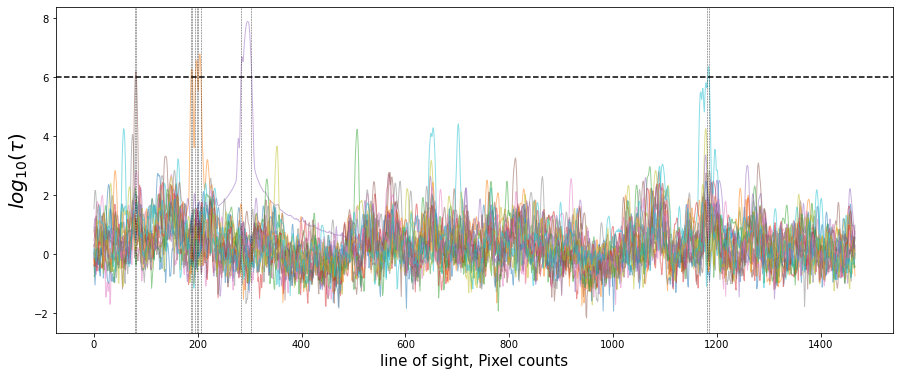

Total number of crossings across all 20 spectra: 12
[[ 186  189]
 [ 195  199]
 [ 201  206]
 [ 283  303]
 [1182 1185]
 [  79   81]]


In [8]:
file_path = 'ns0.859Ap1.29e-09herei3.92heref2.72alphaq1.87hub0.693omegamh20.141hireionz7.15bhfeedback0.0579' 
SNAP = 11
path_append = 'output/' + f'SPECTRA_{SNAP:03d}' + '/lya_forest_spectra_grid_480.hdf5'

# file_path = '/content/drive/MyDrive/output/SPECTRA_011/lya_forest_spectra_grid_480.hdf5'
n_spectra = 20

all_crossing_points = find_DLAs_in_spectrum(file_path, path_append, n_spectra)

num_crossings = len(all_crossing_points)
if num_crossings % 2 != 0:
    paired_crossings = all_crossing_points[:-1]
else:
    paired_crossings = all_crossing_points

if len(paired_crossings) > 0:
    nx2_array = np.column_stack((paired_crossings[::2], paired_crossings[1::2]))
    print(nx2_array)
else:
    print("No crossing points.")

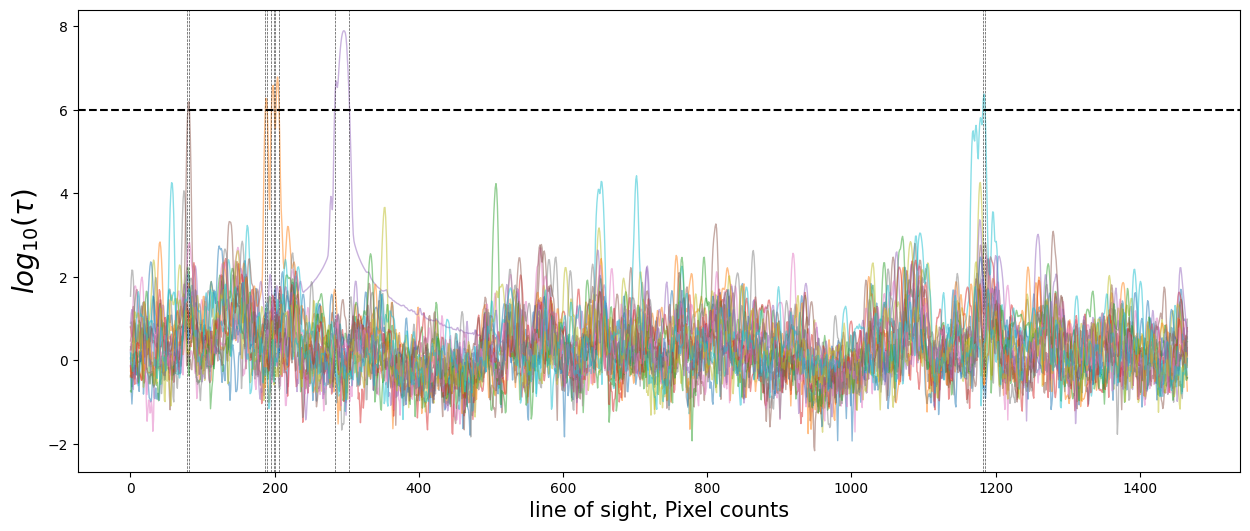

Total number of crossings across all 20 spectra: 12
[[ 186  189]
 [ 195  199]
 [ 201  206]
 [ 283  303]
 [1182 1185]
 [  79   81]]


In [ ]:
file_path = '/content/drive/MyDrive/output/SPECTRA_011/lya_forest_spectra_grid_480.hdf5'
n_spectra = 20

all_crossing_points = find_DLAs_in_spectrum(file_path, n_spectra)

num_crossings = len(all_crossing_points)
if num_crossings % 2 != 0:
    paired_crossings = all_crossing_points[:-1]
else:
    paired_crossings = all_crossing_points

if len(paired_crossings) > 0:
    nx2_array = np.column_stack((paired_crossings[::2], paired_crossings[1::2]))
    print(nx2_array)
else:
    print("No crossing points.")

In [ ]:
# rewrite this and also regenerate the plots with the actual peak which should
# be 1 only for each dla...so 6 in total for the 20 spectra
# also produce the plot again with only the dla spectra

def find_contiguous_regions_above_threshold(data, threshold):
    """Finds start and end indices of contiguous regions where data is above threshold."""
    mask = data > threshold
    segments = []
    in_segment = False
    segment_start = -1
    for k, val in enumerate(mask):
        if val and not in_segment:
            segment_start = k
            in_segment = True
        elif not val and in_segment:
            segments.append((segment_start, k - 1))
            in_segment = False
    if in_segment: # Handle case where data ends above the threshold
        segments.append((segment_start, len(data) - 1))
    return segments

file_path = '/content/drive/MyDrive/output/SPECTRA_011/lya_forest_spectra_grid_480.hdf5'
n_spectra = 20 # Using the same number of spectra as the previous analysis
threshold = 6

all_peaks = []

print(f"Analyzing {n_spectra} spectra for peaks above threshold {threshold}:")

with h5py.File(file_path,'r') as f:
  for i in range(n_spectra):
    tau_spectrum = f['tau/H/1/1215'][i,:]
    log_tau_spectrum = np.log10(tau_spectrum)

    regions = find_contiguous_regions_above_threshold(log_tau_spectrum, threshold)

    for start, end in regions:
      # Extract the segment and find the peak within it
      segment_data = log_tau_spectrum[start:end+1]
      peak_index_in_segment = np.argmax(segment_data)

      # Convert segment-relative peak index to global spectrum index
      global_peak_index = start + peak_index_in_segment
      peak_value = segment_data[peak_index_in_segment]

      all_peaks.append({'spectrum_id': i, 'peak_pixel_count': global_peak_index, 'peak_log_tau': peak_value})

if len(all_peaks) > 0:
  print("\nDetected peaks:")
  for peak in all_peaks:
    print(f"Spectrum {peak['spectrum_id']}: Peak at pixel count {peak['peak_pixel_count']} with log10(tau) = {peak['peak_log_tau']:.2f}")
else:
  print("No peaks found above the threshold in the analyzed spectra.")

Analyzing 20 spectra for peaks above threshold 6:

Detected peaks:
Spectrum 1: Peak at pixel count 188 with log10(tau) = 6.28
Spectrum 1: Peak at pixel count 198 with log10(tau) = 6.59
Spectrum 1: Peak at pixel count 204 with log10(tau) = 6.79
Spectrum 4: Peak at pixel count 296 with log10(tau) = 7.89
Spectrum 9: Peak at pixel count 1184 with log10(tau) = 6.38
Spectrum 15: Peak at pixel count 81 with log10(tau) = 6.20


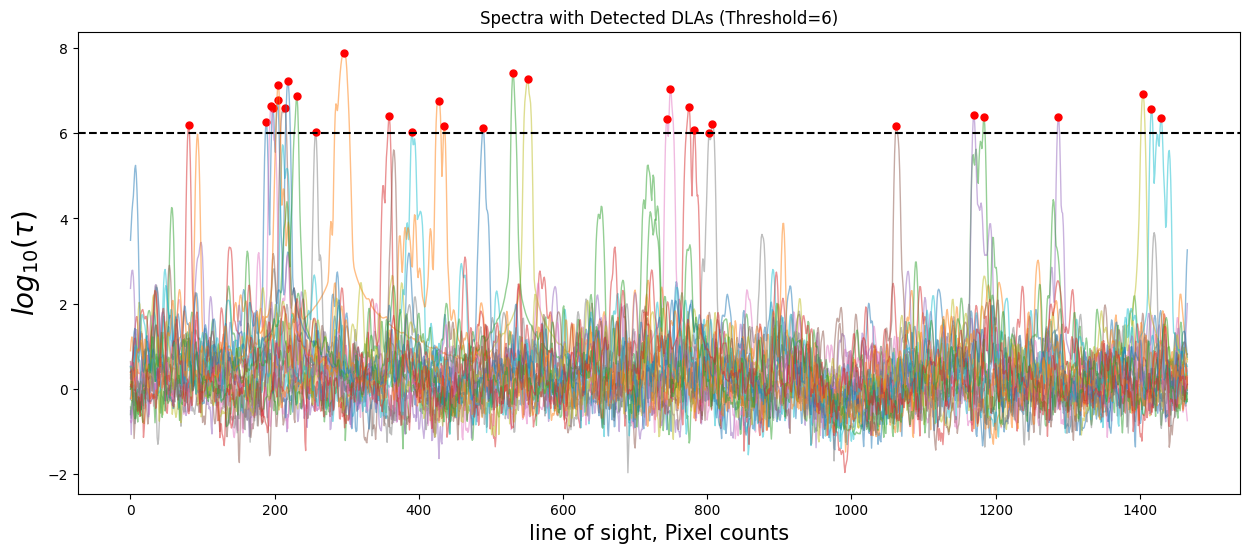

Spectrum 1: sight line: 188, log10(tau) = 6.28
Spectrum 1: sight line: 198, log10(tau) = 6.59
Spectrum 1: sight line: 204, log10(tau) = 6.79
Spectrum 4: sight line: 296, log10(tau) = 7.89
Spectrum 9: sight line: 1184, log10(tau) = 6.38
Spectrum 15: sight line: 81, log10(tau) = 6.20
Spectrum 33: sight line: 1287, log10(tau) = 6.39
Spectrum 120: sight line: 1062, log10(tau) = 6.17
Spectrum 141: sight line: 744, log10(tau) = 6.35
Spectrum 141: sight line: 749, log10(tau) = 7.05
Spectrum 188: sight line: 257, log10(tau) = 6.03
Spectrum 193: sight line: 551, log10(tau) = 7.27
Spectrum 197: sight line: 390, log10(tau) = 6.03
Spectrum 202: sight line: 489, log10(tau) = 6.12
Spectrum 204: sight line: 428, log10(tau) = 6.76
Spectrum 204: sight line: 435, log10(tau) = 6.18
Spectrum 214: sight line: 531, log10(tau) = 7.43
Spectrum 219: sight line: 359, log10(tau) = 6.40
Spectrum 250: sight line: 1170, log10(tau) = 6.43
Spectrum 254: sight line: 214, log10(tau) = 6.59
Spectrum 265: sight line: 195

In [ ]:
# Re-defining the helper function for self-containment
def find_arg_max(data, ythreshold):
    """Finds start and end indices of contiguous regions where data is above ythreshold."""
    mask = data > ythreshold
    segments = []
    in_segment = False
    segment_start = -1
    for k, val in enumerate(mask):
        if val and not in_segment:
            segment_start = k
            in_segment = True
        elif not val and in_segment:
            segments.append((segment_start, k - 1))
            in_segment = False
    if in_segment: # Handle case where data ends above the threshold
        segments.append((segment_start, len(data) - 1))
    return segments

file_path = '/content/drive/MyDrive/output/SPECTRA_011/lya_forest_spectra_grid_480.hdf5'
n_spectra = 300
ythreshold = 6

all_dla_info = [] #start the array to store the info

with h5py.File(file_path,'r') as f:
    for i in range(n_spectra):
        tau_spectrum = f['tau/H/1/1215'][i,:]
        log_tau_spectrum = np.log10(tau_spectrum)

        regions = find_arg_max(log_tau_spectrum, threshold)

        if regions: # If DLA regions are found in this spectrum
            # For each region, find the single highest peak
            for start, end in regions:
                segment_data = log_tau_spectrum[start:end+1]
                peak_index_in_segment = np.argmax(segment_data)
                global_peak_index = start + peak_index_in_segment
                peak_value = segment_data[peak_index_in_segment]

                all_dla_info.append({
                    'spectrum_id': i,
                    'peak_pixel_count': global_peak_index,
                    'peak_log_tau': peak_value,
                    'log_tau_spectrum_data': log_tau_spectrum # Store the entire spectrum for plotting
                })

# plot only the spectra that contain DLAs, marking their peaks
fig, ax = plt.subplots(1, 1, figsize=(15, 6))

plotted_spectrum_ids = set() # To ensure each unique DLA-containing spectrum is plotted only once

for dla_data in all_dla_info:
    spectrum_id = dla_data['spectrum_id']
    if spectrum_id not in plotted_spectrum_ids:
        # Plot the entire spectrum if it hasn't been plotted yet
        ax.plot(np.arange(len(dla_data['log_tau_spectrum_data'])), dla_data['log_tau_spectrum_data'],
                alpha=0.5, linewidth=1, label=f'Spectrum {spectrum_id}') # Add label for the first plot of this spectrum
        plotted_spectrum_ids.add(spectrum_id)

    # Mark the specific peak on the plotted spectrum
    ax.plot(dla_data['peak_pixel_count'], dla_data['peak_log_tau'], 'ro', markersize=5)

ax.axhline(y=threshold, color='black', linestyle='--', label=f'Threshold (y={threshold})')
ax.set_ylabel(r'$log_{10}(\tau)$', fontsize=20)
ax.set_xlabel('line of sight, Pixel counts', fontsize=15)
ax.set_title(f'Spectra with Detected DLAs (Threshold={threshold})')
plt.show()

# Print a summary of DLAs found, similar to d4c91551 output
if len(all_dla_info) > 0:
    # print("\nSummary of detected DLAs (one peak per contiguous region above threshold):")
    for peak in all_dla_info:
        print(f"Spectrum {peak['spectrum_id']}: sight line: {peak['peak_pixel_count']}, log10(tau) = {peak['peak_log_tau']:.2f}")
else:
    print("No DLAs found above the threshold in the analyzed spectra.")

print("Number of spectra:", len(all_dla_info))

In [ ]:
dla_dict = []
for i, dla in enumerate(all_dla_info):
    dla_data = {
        'S.No': i + 1,
        'spect_id': dla['spectrum_id'],
        'x_coord': int(dla['peak_pixel_count']),
        'y_coord': float(dla['peak_log_tau'])
    }
    dla_dict.append(dla_data)

import json
print(json.dumps(dla_dict, indent=2))
# print(dla_dict)

[
  {
    "S.No": 1,
    "spect_id": 1,
    "x_coord": 188,
    "y_coord": 6.2755818367004395
  },
  {
    "S.No": 2,
    "spect_id": 1,
    "x_coord": 198,
    "y_coord": 6.585180282592773
  },
  {
    "S.No": 3,
    "spect_id": 1,
    "x_coord": 204,
    "y_coord": 6.786784648895264
  },
  {
    "S.No": 4,
    "spect_id": 4,
    "x_coord": 296,
    "y_coord": 7.894219398498535
  },
  {
    "S.No": 5,
    "spect_id": 9,
    "x_coord": 1184,
    "y_coord": 6.377840995788574
  },
  {
    "S.No": 6,
    "spect_id": 15,
    "x_coord": 81,
    "y_coord": 6.195306777954102
  },
  {
    "S.No": 7,
    "spect_id": 33,
    "x_coord": 1287,
    "y_coord": 6.389363765716553
  },
  {
    "S.No": 8,
    "spect_id": 120,
    "x_coord": 1062,
    "y_coord": 6.174108982086182
  },
  {
    "S.No": 9,
    "spect_id": 141,
    "x_coord": 744,
    "y_coord": 6.34822416305542
  },
  {
    "S.No": 10,
    "spect_id": 141,
    "x_coord": 749,
    "y_coord": 7.05214262008667
  },
  {
    "S.No": 11,
    "spe

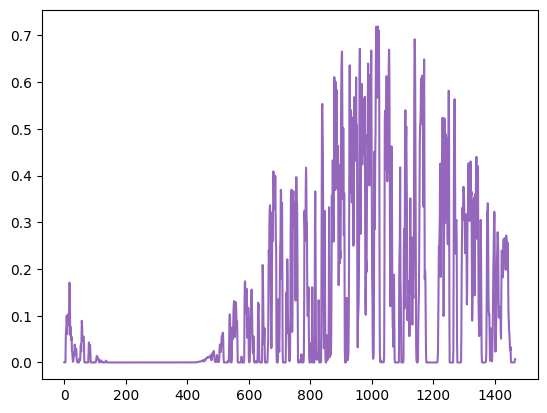

In [ ]:
with h5py.File('/content/drive/MyDrive/output/SPECTRA_011/lya_forest_spectra_grid_480.hdf5','r') as f:
  plt.plot(np.exp(-f['tau/H/1/1215'][4,:]), color='C'+str(4))


Let's download a small `MP-Gadget` simulation with a box size of 15 cMpc/h and $250^3$ particles.

In [ ]:
with h5py.File('/content/drive/MyDrive/output/SPECTRA_011/lya_forest_spectra_grid_480.hdf5','r') as f:
  print(f['tau/H/1/1215'].shape)

(691200, 1467)


In [ ]:
! git clone https://github.com/mahdiqezlou/MP-Gadget_L15n256.git --quiet

^C



It is in [`bigfile`](https://github.com/rainwoodman/bigfile) format which has python module to read/write in python. Very similar to hdf5, but more efficient when writing large simulations.


The simulation data sctructure is pretty standard. We only need the gas particles here.

```
MP-Gadget_L15n256
.
├── PART_020
│   ├── 0 # Gas
│   ├── 1 # Dark matter
│   └── [...]
└── [...]
```

#### Open-MP mode:

The cell below uses only a few cores to generate some spectra from the snapshot. `fake_spectra` is Open-MP parallel, so on HPC systems, you will get a speed boost if more cores on a single node are requested.

Let's get a few random spectra from this snapshot. The cell below calculates the HI column density and optical depth for $Ly\alpha$ and $Ly\beta$ lines. Similarly, you can get the spectra for all other simulated ions.

In [ ]:
from fake_spectra.randspectra import RandSpectra

rr = RandSpectra(num=20, base="./MP-Gadget_L15n256/", numlos=3, thresh=0., res=5., savefile='spectra.hdf5')
# num is the snapshot number, i.e. PART_020
# numlos is the number of randomly positioned spectra you want
# pass thresh=0, otherwise only spectra with total column density above `thresh` are kept
# we set the pixel resolution 5 km/s
rr.get_tau(elem="H",ion=1,line=1215) # ion=1 refers to neutral gas, i.e. HI
                                     # line refers to the wavelength in Ansgtstrom
#Lyman-beta
rr.get_tau(elem="H",ion=1,line=1025)
rr.get_col_density("H",1)
#Save spectra to file
rr.save_file()

OSError: [Errno Not a bigfile or HDF5 snapshot: ] ./MP-Gadget_L15n256/

Below, we visualize the optical depth for a few of these spectra. The solid and dashed curves are $\tau_{Ly\alpha}$ and $\tau_{Ly\beta}$ along each spectrum respectively.

Also, the column dnesity :

In [ ]:
import numpy as np
fig, ax = plt.subplots(1,1, figsize=(15,6))
with h5py.File('/content/drive/MyDrive/output/SPECTRA_011/lya_forest_spectra_grid_480.hdf5','r') as f:
  for i in range(3):
    ax.plot(np.log10(f['tau/H/1/1215'][i,:]))
  #ax.set_ylim(0,5)
  ax.set_ylabel(r'$log_{10}(N_{HI})$', fontsize=20)
  ax.set_xlabel('line of sight, Pixel counts', fontsize=15)

Let's inspect the contents of the HDF5 file you provided to see what datasets are available for plotting.

In [ ]:
import h5py
# ./MP-Gadget_L15n256/SPECTRA_020/spectra.hdf5
# /content/drive/MyDrive/output/SPECTRA_011/lya_forest_spectra_grid_480.hdf5
file_path = '/content/drive/MyDrive/output/SPECTRA_011/lya_forest_spectra_grid_480.hdf5'

print(f"Inspecting file: {file_path}")
with h5py.File(file_path, 'r') as f:
  print("Datasets and Groups in the file:")
  def print_hdf5_item(name, obj):
    print(f"  {name} ({'Group' if isinstance(obj, h5py.Group) else 'Dataset'})")
  f.visititems(print_hdf5_item)


However, sometimes the neutral hydrogen fraction is not stored on the snapshots. `fake_spectra` calculates the HI fraction from gas density and temperature.

The `rate_network` module calculates the HI fraction by assuming ionization equilibrium in the presence of a uniform ultraviolet background (UVB). It solves the collisional/photo-ionization and recombination rate network equations introduced by [Katz et al. (1996), eq. 28-32.](https://arxiv.org/abs/astro-ph/9509107).

 For this, a table containing the photo-ionization/heating of H and He is necessary. We use the table calculated from [radiative transfer simulations](https://arxiv.org/pdf/1903.08657.pdf), i.e. `treecool_file`.

 The self-shielding of dense gas is also implemented by modifying the photoionization rates to the fits provided by radiative transfer codes [`Rahmati et. a1l 2013`](https://ui.adsabs.harvard.edu/abs/2013MNRAS.430.2427R/abstract):

In [ ]:
from fake_spectra.randspectra import RandSpectra
from fake_spectra.ratenetworkspectra import RateNetworkGas
# define global paramters, so people can change them!

rr = RandSpectra(num=20, base="./MP-Gadget_L15n256/", numlos=3, thresh=0, savefile='spectra.hdf5', gasprop=RateNetworkGas,
                gasprop_args={"selfshield":True, "treecool_file":"./MP-Gadget_L15n256/TREECOOL_ep_2018p", "cool":"KWH","recomb":"Cen92"})
rr.get_tau("H",1,1215)
#Lyman-beta
# rr.get_tau("H",1,1025)
rr.get_col_density("H",1)
#Save spectra to file
rr.save_file()

#### MPI-Open-MP mode:

The `MPI` feature of `fake_spectra` helps speed up the post-processing of large snapshots, like the large run of ASTRID (a few TBs), using more nodes on HPC systems.

It is implemented with the `mpi4py` python package.

In [ ]:
! pip install -q mpi4py

 We only need to pass a `mpi4py.MPI` module to `fake_spectra` and run it with `mpirun` or `mpiexec`. The cell below writes a python file to be executed with `mpirun` or `mpiexec`:

In [ ]:
%%sh
cat > MP-Gadget_L15n256/run_mpi.py << EOF
from fake_spectra.randspectra import RandSpectra
# Only if you want the MPI feature; otherwise, MPI is None by default
from mpi4py import MPI
rr = RandSpectra(MPI=MPI, num=20, base="./MP-Gadget_L15n256/", numlos=80, thresh=0, res=5,  savefile='spectra.hdf5')
rr.get_tau("H",1,1215)
#Lyman-beta
rr.get_tau("H",1,1025)
rr.get_col_density("H",1)
#Save spectra to file
rr.save_file()
EOF

In [ ]:
! mpirun --allow-run-as-root python MP-Gadget_L15n256/run_mpi.py

We are not sure how many CPUs we get on Colab, but when running on your won HPC, you can use N ranks with the flag `-np N`.

## Power spectra:
Now, having a few spectra, we can calculate the power spectra, which is the
statistics to emulate in the second half of the tutorial (Ming-Feng's presentation.).

The simulated optical depth for $Ly\alpha$ absorption requires a scaling to match the observed mean flux constrained by [Facher-Giguere et al. 2008](https://iopscience.iop.org/article/10.1086/592289).

In [ ]:
def get_mean_flux(z) :
    """ get the mean flux as function of z, constrained by Faucher-Giguere 2008
    z : redshift
    _________________
    Returns: mean flux
    """
    return np.exp(-0.001330*(1+z)**4.094)

from astropy.cosmology import Planck15 as cosmo
from fake_spectra import fluxstatistics as fs

with h5py.File('/content/drive/MyDrive/output/SPECTRA_011/lya_forest_spectra_grid_480.hdf5','r') as f:
  tau =  f['tau/H/1/1215'][:]
  z = f['Header'].attrs['redshift']
  boxsize = f['Header'].attrs['box']

# The boxsize in units of km/s
vmax = cosmo.H(z).value* boxsize/(1000*(1+z)*cosmo.h)
# The spectral resolution in units of km/s. The power spectrum is divided by this window
spec_res = vmax/tau.shape[1]
k, power_spec = fs.flux_power(tau, vmax= vmax, spec_res= spec_res,
                                  mean_flux_desired=get_mean_flux(z=z))

fig, ax = plt.subplots(1,1)
ax.plot(k, power_spec)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('k [s/km]', fontsize=15)
ax.set_ylabel('P(k)', fontsize=15)

Now, We hear from Ming-Feng telling us how to build a Gaussian Process emulator on these simulated powerspectra.